# XGBoost frente a PyTorch con datos reales de Windward: ¿cuándo merece la pena una red neuronal?

**Resumen del cuaderno.** El objetivo es medir cuándo una red neuronal en PyTorch merece la pena frente a XGBoost (*eXtreme Gradient Boosting*, árboles de decisión potenciados por gradiente) en tres problemas reales del sector eólico. Se comparan XGBoost, un MLP (perceptrón multicapa, *multilayer perceptron*), regresión lineal y persistencia con la misma validación temporal: potencia de turbina con SCADA (sistema de supervisión, control y adquisición de datos de la turbina) de Penmanshiel según la cantidad de datos, extrapolación a vientos más fuertes que los vistos con el lidar (detección y medición por luz láser, *light detection and ranging*) K13A, y previsión de 14 turbinas a 12 horizontes (168 salidas). Resultados principales: XGBoost gana o empata con datos tabulares (30,9 kW de MAE (error absoluto medio) frente a 31,3 kW del MLP con todos los datos, y mucho mejor con pocos); fuera del rango de entrenamiento un árbol falla (RMSE, raíz del error cuadrático medio, de 5,4 m/s) y una red sigue la tendencia sin precisión (1,3 m/s), mientras que un modelo lineal o XGBoost con el objetivo bien elegido llegan a 0,8 y 0,9 m/s; y con muchas salidas relacionadas un único MLP empata en media, gana a partir de 4 h de horizonte (un 2 %) y se entrena unas 9 veces más rápido. Las redes son imprescindibles cuando la entrada no es una tabla (imágenes, grafos), que es lo que tratan los otros cuadernos.

**Objetivo de la sesión.** Comparar, con la misma validación temporal y con un rival bien ajustado, un modelo de árboles (XGBoost) con una red neuronal escrita en PyTorch sobre tres problemas reales del sector eólico. El objetivo no es que gane PyTorch: es medir **dónde** gana cada uno y **por qué**, para decidir con criterio cuándo usar cada herramienta.

| Experimento | Datos reales | Pregunta |
|---|---|---|
| 1. Potencia de cada turbina desde el SCADA | Penmanshiel, 14 turbinas, 30 min | ¿Cuántos datos hacen falta para que una red alcance a XGBoost? |
| 2. Salir del rango de entrenamiento | Lidar marino K13A (Mar del Norte, 2017) | ¿Qué pasa cuando llega un viento más fuerte que el visto en entrenamiento? |
| 3. Previsión multi-horizonte y multi-turbina | Penmanshiel, 14 turbinas, de 30 min a 6 h | ¿Un modelo con 168 salidas compite con 12 modelos de XGBoost? |

**Qué vas a aprender**

1. A montar una comparación justa: test temporal, parada temprana en ambos modelos, varias semillas y el rival con sus mejores rasgos.
2. Por qué los árboles **no extrapolan** y qué hace una red en ese caso.
3. Qué ventajas reales tiene una red cuando hay **muchas salidas** que comparten estructura.
4. Un **mapa de decisión** con los números de este cuaderno, y qué problemas del curso (imágenes SAR (radar de apertura sintética, *synthetic aperture radar*), grafos, física) solo se pueden abordar con redes.

**Aviso desde el principio.** Los resultados son los que salen al ejecutar. En datos tabulares de tamaño moderado XGBoost gana o empata casi siempre; lo que sigue explica por qué y en qué casos cambia la cosa.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/wind_cases/04_xgboost_vs_pytorch.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta y descarga la carpeta `datos/` del repositorio. Los tiempos de este cuaderno se midieron en un equipo con varios núcleos; un entorno de CPU gratuito de Colab (unos 2 núcleos) puede tardar varias veces más.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan y, en Colab,
# descarga la carpeta datos/ (unos 22 MB) del repositorio del curso si no está junto al cuaderno.
import importlib.util, os, shutil, subprocess, sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'xgboost': 'xgboost',
}  # nombre de importación -> requisito de pip
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

REPO = 'https://github.com/fborbon/academy.git'         # repositorio del curso (carpeta neural-networks-1002/wind_cases)
if not Path('datos').exists():
    print('Descargando datos/ del repositorio del curso ...')
    tmp = Path('_repo_curso')
    shutil.rmtree(tmp, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', REPO, str(tmp)], check=True)
    subprocess.run(['git', '-C', str(tmp), 'sparse-checkout', 'set', 'neural-networks-1002/wind_cases/datos'], check=True)
    shutil.copytree(tmp / 'neural-networks-1002' / 'wind_cases' / 'datos', 'datos')
    shutil.rmtree(tmp, ignore_errors=True)
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()} | datos/: {len(list(Path('datos').glob('*')))} archivos")

Entorno: Python 3.12.3 | local | CPUs: 8 | datos/: 20 archivos


<!-- toc -->
**Contenido**

* [1. Entorno y semillas](#1.-Entorno-y-semillas)
* [2. Los datos](#2.-Los-datos)
* [3. Experimento 1: potencia de una turbina desde el SCADA, según la cantidad de datos](#3.-Experimento-1:-potencia-de-una-turbina-desde-el-SCADA,-según-la-cantidad-de-datos)
* [4. Experimento 2: ¿y si llega un viento más fuerte que el visto en entrenamiento?](#4.-Experimento-2:-¿y-si-llega-un-viento-más-fuerte-que-el-visto-en-entrenamiento?)
* [5. Experimento 3: previsión multi-horizonte y multi-turbina](#5.-Experimento-3:-previsión-multi-horizonte-y-multi-turbina)
* [6. Mapa de decisión: cuándo merece la pena PyTorch](#6.-Mapa-de-decisión:-cuándo-merece-la-pena-PyTorch)
* [7. Limitaciones y ejercicios](#7.-Limitaciones-y-ejercicios)

*Para saltar a una sección usa el índice del panel lateral izquierdo: en JupyterLab la pestaña "Table of Contents" y en VS Code la vista "Outline" (se generan solas a partir de los títulos). Los enlaces de esta lista llevan bien a las secciones cercanas, pero JupyterLab no siempre llega a las lejanas porque no dibuja todas las celdas a la vez.*


## 1. Entorno y semillas

Semillas fijas y CPU (unidad central de procesamiento). El cuaderno tarda unos 10 minutos, casi un tercio en entrenar los 12 modelos de XGBoost del experimento 3. Necesita `xgboost` además de lo que ya usan los otros cuadernos.

In [1]:
import os
import time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xgboost as xgb
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt

SEMILLA = 0
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATOS = Path("datos")
T0 = time.time()  # para medir el tiempo total de ejecución
print("torch", torch.__version__, "| xgboost", xgb.__version__)

torch 2.15.0+cpu | xgboost 3.4.1



## 2. Los datos

**SCADA de Penmanshiel** (14 turbinas de 2,05 MW, Escocia, CC BY 4.0 (Creative Commons Atribución), Zenodo), promediado a 30 min: potencia, viento de góndola, dirección y temperatura. A cada fila le añadimos el **contexto del parque** (viento medio y dispersión entre turbinas en ese instante) y la hora del día. Todos los experimentos con SCADA usan el mismo corte temporal, sin mezclar épocas:

* entrenamiento: enero de 2018 a marzo de 2019,
* validación (parada temprana): abril a junio de 2019,
* test: julio a diciembre de 2019.

**Lidar K13A** (plataforma en el Mar del Norte, 2017) para el experimento 2; se describe allí. Todos los extractos están en `datos/`.

In [2]:
scada = pd.read_parquet(DATOS / "gnn_scada_penmanshiel_kelmarsh_30min.parquet")
g = scada[scada.granja == "penmanshiel"].copy()
g["tid"] = g.turbina.astype(str).astype("category").cat.codes.astype("int64")   # identificador de turbina 0..13
rad = np.deg2rad(g.direccion_deg)
g["dir_sen"], g["dir_cos"] = np.sin(rad), np.cos(rad)
# contexto del parque en cada instante: viento medio y dispersión entre turbinas
ctx = g.groupby("timestamp").viento_ms.agg(["mean", "std", "count"])
ctx.columns = ["u_parque", "u_std", "n_turb"]
g = g.join(ctx, on="timestamp")
g = g[g.n_turb >= 10].copy()
g["h_sen"] = np.sin(2 * np.pi * g.timestamp.dt.hour / 24)
g["h_cos"] = np.cos(2 * np.pi * g.timestamp.dt.hour / 24)
P_NOM = 2050.0   # kW, potencia nominal de las turbinas de Penmanshiel

F1 = ["viento_ms", "dir_sen", "dir_cos", "temp_c", "u_parque", "u_std", "h_sen", "h_cos", "tid"]
tr1 = g[g.timestamp < "2019-04-01"]
va1 = g[(g.timestamp >= "2019-04-01") & (g.timestamp < "2019-07-01")]
te1 = g[g.timestamp >= "2019-07-01"]
print(f"filas: entrenamiento {len(tr1):,}, validación {len(va1):,}, test {len(te1):,}")
display(g[["timestamp", "turbina", "potencia_kw"] + F1[:-1]].head(4).round(2))

filas: entrenamiento 268,086, validación 55,776, test 103,208


/tmp/ipykernel_1883444/246226713.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(g[["timestamp", "turbina", "potencia_kw"] + F1[:-1]].head(4).round(2))


,timestamp,turbina,potencia_kw,viento_ms,dir_sen,dir_cos,temp_c,u_parque,u_std,h_sen,h_cos
199842,2018-01-01 03:00:00,Penmanshiel_01,201.0,5.34,-0.63,-0.77,3.9,5.06,0.48,0.71,0.71
199843,2018-01-01 11:00:00,Penmanshiel_01,44.0,4.37,-0.96,0.29,8.1,4.72,0.70,0.26,-0.97
199844,2018-01-01 11:30:00,Penmanshiel_01,130.0,5.00,-0.68,-0.73,6.4,4.73,0.38,0.26,-0.97
199845,2018-01-01 12:00:00,Penmanshiel_01,198.0,5.39,-0.88,-0.48,6.3,4.76,0.62,0.00,-1.00



## 3. Experimento 1: potencia de una turbina desde el SCADA, según la cantidad de datos

**Problema.** Predecir la potencia de una turbina en un instante conocido a partir de su viento, la dirección (seno y coseno), la temperatura, el viento medio y la dispersión del parque, la hora y la turbina. Es el problema tabular típico: pocas columnas heterogéneas, relación casi suave.

**Los dos rivales, con el mismo cuidado**

* **XGBoost**: hasta 2000 árboles, tasa 0,05, submuestreo, parada temprana con la validación.
* **MLP en PyTorch**: tres capas ocultas (128, 128, 64), un *embedding* de 4 dimensiones por turbina, entradas normalizadas, pérdida L1 (suma de diferencias absolutas), Adam y parada temprana con la misma validación.

Repetimos el entrenamiento con 500, 2 000, 10 000, 50 000 y todas las filas (268 000), eligiendo las filas al azar dentro del periodo de entrenamiento. El test es siempre el mismo (jul a dic de 2019). El MLP se entrena con 3 semillas; la franja de la figura es su rango.

In [3]:
def fit_xgb1(tr, va, n_max=2000, prof=5):
    m = xgb.XGBRegressor(n_estimators=n_max, learning_rate=0.05, max_depth=prof, subsample=0.8,
                         colsample_bytree=0.8, early_stopping_rounds=50, n_jobs=8)
    m.fit(tr[F1], tr.potencia_kw / P_NOM, eval_set=[(va[F1], va.potencia_kw / P_NOM)], verbose=False)
    return m

F1_NUM = F1[:-1]
MU1, SD1 = tr1[F1_NUM].mean(), tr1[F1_NUM].std()

def tensores1(d):
    x = torch.tensor(((d[F1_NUM] - MU1) / SD1).fillna(0).values, dtype=torch.float32)
    return x, torch.tensor(d.tid.values), torch.tensor(d.potencia_kw.values / P_NOM, dtype=torch.float32)

class MLPTurbina(nn.Module):
    """MLP con embedding de turbina: 3 capas ocultas."""
    def __init__(self, n_in=len(F1_NUM)):
        super().__init__()
        self.emb = nn.Embedding(14, 4)
        self.f = nn.Sequential(nn.Linear(n_in + 4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(),
                               nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, i):
        return self.f(torch.cat([x, self.emb(i)], 1)).squeeze(1)

def fit_mlp1(tr, va, semilla, epocas, lote):
    torch.manual_seed(semilla)
    net, opt = MLPTurbina(), None
    opt = torch.optim.Adam(net.parameters(), 2e-3)
    xt, it, yt = tensores1(tr); xv, iv, yv = tensores1(va)
    mejor = (9e9, None)
    for ep in range(epocas):
        net.train(); perm = torch.randperm(len(xt))
        for i in range(0, len(perm), lote):
            b = perm[i:i + lote]
            opt.zero_grad(); (net(xt[b], it[b]) - yt[b]).abs().mean().backward(); opt.step()
        net.eval()
        with torch.no_grad():
            v = (net(xv, iv) - yv).abs().mean().item()
        if v < mejor[0]:
            mejor = (v, copy.deepcopy(net.state_dict()))
    net.load_state_dict(mejor[1])
    return net.eval()

XE, IE, YE = tensores1(te1)
mae_kw = lambda p: float(np.abs(np.asarray(p) - YE.numpy()).mean() * P_NOM)

In [4]:
rng = np.random.default_rng(SEMILLA)
TAMANOS = [500, 2000, 10000, 50000, len(tr1)]
filas1 = []
for n in TAMANOS:
    t0 = time.time()
    if n < len(tr1):
        tr_n = tr1.iloc[np.sort(rng.choice(len(tr1), n, replace=False))]
        va_n = va1.iloc[np.sort(rng.choice(len(va1), max(n // 4, 300), replace=False))]
    else:
        tr_n, va_n = tr1, va1
    m = fit_xgb1(tr_n, va_n, prof=5 if n < 50000 else 7)
    e_x, t_x = mae_kw(m.predict(te1[F1])), time.time() - t0
    t0 = time.time(); e_m = []
    epocas, lote = (60, 128) if n <= 10000 else ((25, 512) if n < len(tr1) else (20, 1024))
    for s in range(3):
        net = fit_mlp1(tr_n, va_n, s, epocas, lote)
        with torch.no_grad():
            e_m.append(mae_kw(net(XE, IE).numpy()))
    t_m = (time.time() - t0) / 3
    filas1.append(dict(n_entrenamiento=n, xgb_kW=e_x, mlp_kW=np.mean(e_m), mlp_min=min(e_m), mlp_max=max(e_m),
                       xgb_s=t_x, mlp_s_por_semilla=t_m))
    print(f"n={n:>7,}  XGBoost {e_x:6.2f} kW ({t_x:5.1f} s)   MLP {np.mean(e_m):6.2f} kW [{min(e_m):.2f} a {max(e_m):.2f}] ({t_m:5.1f} s por semilla)")
res1 = pd.DataFrame(filas1)
res1.round(2)

n=    500  XGBoost  41.64 kW (  0.5 s)   MLP  62.53 kW [57.63 a 68.59] (  2.3 s por semilla)


n=  2,000  XGBoost  37.62 kW (  0.4 s)   MLP  43.23 kW [42.09 a 44.31] (  3.5 s por semilla)


n= 10,000  XGBoost  33.10 kW (  1.4 s)   MLP  36.86 kW [36.51 a 37.11] ( 25.0 s por semilla)


n= 50,000  XGBoost  31.71 kW (  3.4 s)   MLP  33.20 kW [33.03 a 33.51] ( 22.5 s por semilla)


n=268,086  XGBoost  30.90 kW ( 14.4 s)   MLP  31.31 kW [31.08 a 31.72] ( 44.0 s por semilla)


,n_entrenamiento,xgb_kW,mlp_kW,mlp_min,mlp_max,xgb_s,mlp_s_por_semilla
0,500,41.64,62.53,57.63,68.59,0.47,2.28
1,2000,37.62,43.23,42.09,44.31,0.39,3.45
2,10000,33.10,36.86,36.51,37.11,1.44,25.00
3,50000,31.71,33.20,33.03,33.51,3.41,22.49
4,268086,30.90,31.31,31.08,31.72,14.38,43.98


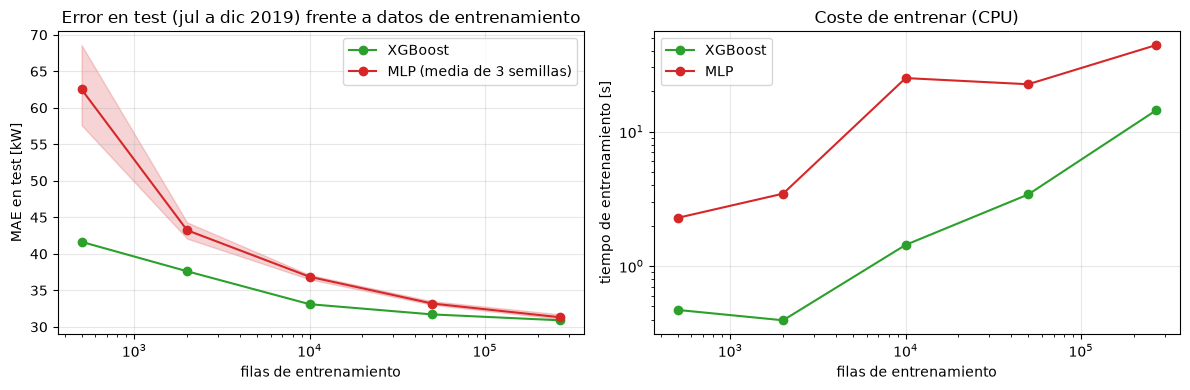

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ax = axs[0]
ax.plot(res1.n_entrenamiento, res1.xgb_kW, "o-", color="tab:green", label="XGBoost")
ax.plot(res1.n_entrenamiento, res1.mlp_kW, "o-", color="tab:red", label="MLP (media de 3 semillas)")
ax.fill_between(res1.n_entrenamiento, res1.mlp_min, res1.mlp_max, color="tab:red", alpha=0.2)
ax.set_xscale("log"); ax.set_xlabel("filas de entrenamiento"); ax.set_ylabel("MAE en test [kW]")
ax.set_title("Error en test (jul a dic 2019) frente a datos de entrenamiento"); ax.legend()
ax = axs[1]
ax.plot(res1.n_entrenamiento, res1.xgb_s, "o-", color="tab:green", label="XGBoost")
ax.plot(res1.n_entrenamiento, res1.mlp_s_por_semilla, "o-", color="tab:red", label="MLP")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("filas de entrenamiento"); ax.set_ylabel("tiempo de entrenamiento [s]")
ax.set_title("Coste de entrenar (CPU)"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura:**

* **XGBoost gana en todos los tamaños.** Con 500 filas la diferencia es enorme (41,6 kW de MAE frente a 62,5 kW de media del MLP, con semillas entre 57,6 y 68,6 kW). Con 2 000 filas, 37,6 frente a 43,2 kW. Con 10 000, 33,1 frente a 36,9 kW. La red necesita muchos datos para aprender, desde cero, una curva de potencia que un árbol ya aproxima con pocos cortes.
* **Con todos los datos se acercan, pero no se cruzan.** Con 268 000 filas XGBoost da 30,90 kW y el MLP 31,31 kW (31,08 a 31,72 según la semilla): las tres semillas quedan por detrás. La diferencia ya es de un 1 %, del tamaño del ruido de una semilla.
* **El coste es muy distinto.** Con todos los datos XGBoost tarda unos 14 s; el MLP, unos 44 s por semilla en CPU. Con 10 000 filas la proporción es de 1 a 17 (1,4 s frente a 25,0 s), porque el MLP hace 60 épocas con lotes pequeños.
* **Qué significa.** El error de unos 31 kW (un 1,5 % de la potencia nominal) es casi todo ruido de medida y de turbulencia: ningún modelo lo baja mucho más. Cuando el problema es tabular, de dimensión baja y suave, una red grande no encuentra estructura que a los árboles se les escape.


## 4. Experimento 2: ¿y si llega un viento más fuerte que el visto en entrenamiento?

**Problema (lidar K13A).** Predecir el viento a 191, 216, 241, 266 y 291 m a partir de lo medido a 63, 91, 116 y 141 m más la dirección (extrapolación vertical, como en el cuaderno 01 pero ahora con modelos de datos). Cinco salidas.

**Dos divisiones del mismo registro**

* **A. Temporal:** se entrena con enero a agosto y se prueba con septiembre a diciembre. Es la validación honesta de una campaña real.
* **B. Fuera de rango:** se entrena **solo con los instantes con viento a 116 m por debajo de 10 m/s** (a 141 m el máximo visto es 11 m/s) y se prueba con los de 10 m/s o más, que llegan hasta 31,7 m/s. Es el caso de una campaña corta en una estación tranquila que luego se aplica en una tormenta.

**Modelos**

| Modelo | Idea |
|---|---|
| Persistencia | El viento a 141 m se repite en todas las alturas |
| Regresión lineal (Ridge) | Una recta por altura; es lo más simple que existe |
| XGBoost, objetivo directo | Predice el viento a cada altura tal cual |
| XGBoost, objetivo = cociente | Predice el cociente (viento a esa altura) / (viento a 141 m) y se multiplica después. Es **ingeniería de rasgos con conocimiento físico**: la cizalladura es casi un cociente |
| MLP | Dos capas de 64, error cuadrático, parada temprana |
| MLP con salto lineal | El MLP más una capa lineal directa de la entrada a la salida |

Los modelos de PyTorch se entrenan con 3 semillas y se informa la media. La métrica es el RMSE en m/s sobre las cinco alturas.

In [6]:
lid = pd.read_csv(DATOS / "k13a_lidar_2017_10min.csv.gz", parse_dates=["timestamp_utc"]).dropna().sort_values("timestamp_utc")
cols_ws = [c for c in lid.columns if c.startswith("ws_")]
ENTRADAS, SALIDAS = cols_ws[:4], cols_ws[5:]        # 63 a 141 m  ->  191 a 291 m  (se salta 166 m)
print("entradas:", ENTRADAS, "\nsalidas: ", SALIDAS)
rad = np.deg2rad(lid.wd_116.values)
X2 = np.c_[lid[ENTRADAS].values, np.sin(rad), np.cos(rad)]
Y2 = lid[SALIDAS].values
mes = lid.timestamp_utc.dt.month.values
print(f"{len(lid):,} registros de 10 min; meses disponibles: {sorted(set(mes))}")
print("viento medio a 116 m por mes [m/s]:", lid.groupby(mes).ws_116.mean().round(1).to_dict())

DIVISIONES = {
    "A. temporal (entrena ene a ago, prueba sep a dic)": (mes <= 8, mes > 8),
    "B. fuera de rango (entrena con ws_116 < 10 m/s, prueba con >= 10 m/s)": (lid.ws_116.values < 10, lid.ws_116.values >= 10),
}
for k, (a, b) in DIVISIONES.items():
    print(f"{k}: {a.sum():,} de entrenamiento, {b.sum():,} de test; ws_141 máx. entrenamiento {X2[a, 3].max():.1f} m/s, máx. test {X2[b, 3].max():.1f} m/s")

entradas: ['ws_63', 'ws_91', 'ws_116', 'ws_141'] 
salidas:  ['ws_191', 'ws_216', 'ws_241', 'ws_266', 'ws_291']
29,051 registros de 10 min; meses disponibles: [np.int32(1), np.int32(2), np.int32(3), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]
viento medio a 116 m por mes [m/s]: {1: 9.9, 2: 12.6, 3: 9.3, 8: 6.6, 9: 8.6, 10: 12.9, 11: 11.1, 12: 12.4}
A. temporal (entrena ene a ago, prueba sep a dic): 12,269 de entrenamiento, 16,782 de test; ws_141 máx. entrenamiento 28.6 m/s, máx. test 31.7 m/s
B. fuera de rango (entrena con ws_116 < 10 m/s, prueba con >= 10 m/s): 13,056 de entrenamiento, 15,995 de test; ws_141 máx. entrenamiento 11.0 m/s, máx. test 31.7 m/s


Definimos los modelos y una función que los entrena todos con un conjunto de entrenamiento y devuelve sus predicciones en test. El 15 % final del entrenamiento, en orden temporal, hace de validación para la parada temprana de XGBoost y del MLP.

In [7]:
class MLPLidar(nn.Module):
    """MLP pequeño; con salto lineal=True suma una capa lineal directa de la entrada a la salida."""
    def __init__(self, salto_lineal):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(6, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, Y2.shape[1]))
        self.lin = nn.Linear(6, Y2.shape[1]) if salto_lineal else None
    def forward(self, x):
        return self.f(x) + (self.lin(x) if self.lin is not None else 0)

def modelos_lidar(Xtr, Ytr, Xte, semillas=3):
    """Devuelve {modelo: predicción en test} (los de PyTorch, media de las predicciones de 3 semillas se evalúa por separado)."""
    n = len(Xtr); ntr = int(0.85 * n)           # el 15 % final del entrenamiento (en orden temporal) es la validación
    sal = {}
    sal["persistencia (ws_141 en todas las alturas)"] = [np.repeat(Xte[:, 3:4], Y2.shape[1], 1)]
    sal["regresión lineal (Ridge)"] = [Ridge(1e-3).fit(Xtr, Ytr).predict(Xte)]
    for nombre, objetivo_ratio in [("XGBoost, objetivo directo", False), ("XGBoost, objetivo = cociente con ws_141", True)]:
        p = np.zeros((len(Xte), Y2.shape[1]))
        for j in range(Y2.shape[1]):
            den_tr = Xtr[:, 3] if objetivo_ratio else 1.0
            den_te = Xte[:, 3] if objetivo_ratio else 1.0
            y = Ytr[:, j] / den_tr
            m = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, early_stopping_rounds=30, n_jobs=8)
            m.fit(Xtr[:ntr], y[:ntr], eval_set=[(Xtr[ntr:], y[ntr:])], verbose=False)
            p[:, j] = m.predict(Xte) * den_te
        sal[nombre] = [p]
    mu, sd = Xtr.mean(0), Xtr.std(0)
    xt = torch.tensor((Xtr - mu) / sd, dtype=torch.float32); yt = torch.tensor(Ytr, dtype=torch.float32)
    xe = torch.tensor((Xte - mu) / sd, dtype=torch.float32)
    for nombre, salto in [("MLP", False), ("MLP con salto lineal", True)]:
        sal[nombre] = []
        for s in range(semillas):
            torch.manual_seed(s); net = MLPLidar(salto); opt = torch.optim.Adam(net.parameters(), 2e-3)
            mejor = (9e9, None)
            for ep in range(40):
                net.train(); perm = torch.randperm(ntr)
                for i in range(0, ntr, 256):
                    b = perm[i:i + 256]
                    opt.zero_grad(); ((net(xt[b]) - yt[b]) ** 2).mean().backward(); opt.step()
                net.eval()
                with torch.no_grad():
                    v = ((net(xt[ntr:]) - yt[ntr:]) ** 2).mean().item()
                if v < mejor[0]:
                    mejor = (v, copy.deepcopy(net.state_dict()))
            net.load_state_dict(mejor[1]); net.eval()
            with torch.no_grad():
                sal[nombre].append(net(xe).numpy())
    return sal

In [8]:
t_e2 = time.time()
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
PRED2, tabla2 = {}, {}
for nombre_div, (mtr, mte) in DIVISIONES.items():
    sal = modelos_lidar(X2[mtr], Y2[mtr], X2[mte])
    PRED2[nombre_div] = sal
    tabla2[nombre_div] = {k: np.mean([rmse(p, Y2[mte]) for p in v]) for k, v in sal.items()}
tabla2 = pd.DataFrame(tabla2)
tabla2.columns = ["A. temporal", "B. fuera de rango"]
print(f"tiempo de este experimento: {time.time() - t_e2:.0f} s")
tabla2.round(3)

tiempo de este experimento: 62 s


,A. temporal,B. fuera de rango
persistencia (ws_141 en todas las alturas),0.811,1.100
regresión lineal (Ridge),0.566,0.839
"XGBoost, objetivo directo",0.628,5.434
"XGBoost, objetivo = cociente con ws_141",0.652,0.923
MLP,0.622,1.430
MLP con salto lineal,0.609,1.320


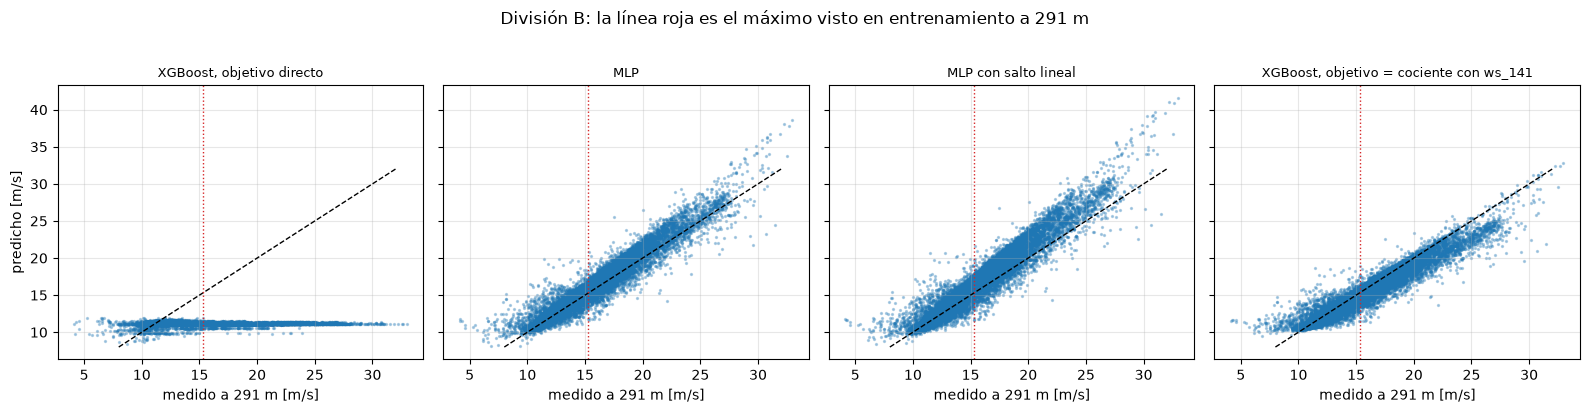

In [9]:
nombre_B = list(DIVISIONES)[1]; mte_B = DIVISIONES[nombre_B][1]
yB = Y2[mte_B][:, -1]               # altura de 291 m
fig, axs = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, k in zip(axs, ["XGBoost, objetivo directo", "MLP", "MLP con salto lineal", "XGBoost, objetivo = cociente con ws_141"]):
    p = PRED2[nombre_B][k][0][:, -1]
    ax.scatter(yB, p, s=2, alpha=0.3)
    ax.plot([8, 32], [8, 32], "k--", lw=1)
    ax.axvline(Y2[DIVISIONES[nombre_B][0]][:, -1].max(), color="tab:red", lw=1, ls=":")
    ax.set_title(k, fontsize=9); ax.set_xlabel("medido a 291 m [m/s]")
axs[0].set_ylabel("predicho [m/s]")
plt.suptitle("División B: la línea roja es el máximo visto en entrenamiento a 291 m", y=1.02)
plt.tight_layout(); plt.show()

**Lectura:**

* **División B: XGBoost directo falla por completo (RMSE 5,43 m/s).** En la figura se ve por qué: predice una línea plana en torno a 11 m/s, que es lo máximo que vio. Un árbol devuelve un promedio de los valores de entrenamiento de su hoja, así que **no puede salir del rango de los objetivos de entrenamiento**. No es un problema de ajuste de hiperparámetros: es una propiedad del modelo.
* **El MLP sí sigue la tendencia, pero sin precisión.** El MLP con salto lineal da 1,32 m/s y el MLP simple 1,43 m/s. La figura muestra que ambos continúan la diagonal; la red con salto sobreestima, porque extrapola una pendiente aprendida en vientos moderados. **Ni siquiera supera a la persistencia (1,10 m/s)**: extrapolar es mejor que no poder hacerlo, pero no es fiable.
* **Dos soluciones mejores que la red:** la regresión lineal (0,84 m/s) y XGBoost con el objetivo en forma de cociente (0,92 m/s). Ambas incorporan la física (la cizalladura es casi proporcional al viento de referencia). **Con conocimiento del dominio, el árbol vuelve a ser competitivo**; sin él, falla.
* **División A (temporal), sin salir de rango:** de nuevo gana la regresión lineal (0,566), seguida del MLP con salto (0,609), el MLP (0,622), XGBoost directo (0,628) y XGBoost con cociente (0,652). Las diferencias entre modelos aprendidos son de un 3 a un 7 %, pequeñas, y el modelo más simple las supera a todas. La persistencia da 0,811.
* **Conclusión del experimento.** La ventaja de PyTorch aquí es **no necesitar el truco** del cociente y degradarse con suavidad, no ganar. Si se conoce la física, un modelo lineal o un XGBoost con el objetivo bien elegido hacen más con menos. Una red es un seguro cuando no se sabe cómo transformar el problema, pero conviene vigilar el rango de entrada (¿hay datos fuera del visto?) como parte del despliegue.


## 5. Experimento 3: previsión multi-horizonte y multi-turbina

**Problema.** Con las últimas 3 horas del SCADA (6 pasos de 30 min) predecir la potencia de **cada una de las 14 turbinas** en los 12 horizontes siguientes, de 30 min a 6 h. Son 168 salidas por muestra, con una estructura obvia: salidas cercanas en el tiempo y en el espacio se parecen.

**Los dos rivales**

* **XGBoost, bien servido:** un modelo por horizonte (12), con pérdida L1 (`reg:absoluteerror`), parada temprana y 67 rasgos por fila (turbina, instante): su propia historia de potencia, viento y dirección, las medias del parque, **la potencia y el viento actuales de las 14 turbinas**, la hora y la turbina. Cada fila es un par (instante, turbina), así que cada modelo ve 14 veces más filas.
* **Un único MLP**: recibe la historia de todas las turbinas aplanada (336 números más la hora) y devuelve las 168 salidas a la vez, con pérdida L1 media. Dos capas de 512 y parada temprana. Tres semillas.

Referencia: **persistencia** (la potencia actual se repite en todos los horizontes). Métrica: MAE en tanto por ciento de la potencia nominal, en el test de julio a diciembre de 2019.

In [10]:
LAG, H = 6, 12                      # 6 pasos de 30 min de historia (3 h), 12 horizontes (de 30 min a 6 h)
pen = scada[scada.granja == "penmanshiel"]
M = {k: pen.pivot(index="timestamp", columns="turbina", values=c).astype("float32")
     for k, c in [("P", "potencia_kw"), ("U", "viento_ms"), ("D", "direccion_deg")]}
full = pd.date_range(M["P"].index.min(), M["P"].index.max(), freq="30min")
M = {k: v.reindex(full).interpolate(limit=4) for k, v in M.items()}      # huecos de hasta 2 h se interpolan
Pn, Un, th_ = M["P"].values / P_NOM, M["U"].values / 15, np.deg2rad(M["D"].values)
Pn = np.clip(Pn, 0, 1.2)
bien = ~(np.isnan(Pn).any(1) | np.isnan(Un).any(1) | np.isnan(th_).any(1))
sen_d, cos_d = np.sin(th_), np.cos(th_)
hh = full.hour.values + full.minute.values / 60
tf = np.c_[np.sin(2 * np.pi * hh / 24), np.cos(2 * np.pi * hh / 24)]
N = Pn.shape[1]
ts = np.array([t for t in range(LAG - 1, len(full) - H) if bien[t - LAG + 1:t + H + 1].all()])
tm = full[ts]
tr3, va3 = ts[tm < "2019-04-01"], ts[(tm >= "2019-04-01") & (tm < "2019-07-01")]
te3 = ts[tm >= "2019-07-01"]
print(f"{N} turbinas; muestras: entrenamiento {len(tr3):,}, validación {len(va3):,}, test {len(te3):,}")

def historia(t):      # (B, LAG, N, 4): potencia, viento, sen y cos de la dirección
    return np.stack([np.stack([Pn[t - k], Un[t - k], sen_d[t - k], cos_d[t - k]], -1) for k in range(LAG)], 1)

def objetivo(t):      # (B, H, N)
    return np.stack([Pn[t + h] for h in range(1, H + 1)], 1)

def rasgos_xgb(t):
    """Una fila por (instante, turbina): historia propia, medias del parque, P y U actuales de todas las turbinas, hora, turbina."""
    a = historia(t); B = len(t)
    propio = a.transpose(0, 2, 1, 3).reshape(B, N, LAG * 4)
    parque = a[..., :2].mean(2).reshape(B, 1, -1).repeat(N, 1)
    todas = np.concatenate([Pn[t], Un[t]], 1)[:, None].repeat(N, 1)
    extra = np.concatenate([tf[t][:, None].repeat(N, 1), np.broadcast_to(np.arange(N)[None, :, None], (B, N, 1))], -1)
    return np.concatenate([propio, parque, todas, extra], -1).reshape(B * N, -1)

Xx_tr, Xx_va, Xx_te = rasgos_xgb(tr3), rasgos_xgb(va3), rasgos_xgb(te3)
Y_tr, Y_va, Y_te = objetivo(tr3), objetivo(va3), objetivo(te3)
print("rasgos por fila para XGBoost:", Xx_tr.shape[1], "| salidas por muestra para la red:", H * N)

14 turbinas; muestras: entrenamiento 18,508, validación 3,781, test 7,082


rasgos por fila para XGBoost: 67 | salidas por muestra para la red: 168


In [11]:
t0 = time.time()
pred_x = np.zeros_like(Y_te)
for h in range(H):                          # un modelo por horizonte (la misma fila sirve para las 14 turbinas)
    m = xgb.XGBRegressor(objective="reg:absoluteerror", n_estimators=600, learning_rate=0.1, max_depth=6,
                         subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=40, n_jobs=8)
    m.fit(Xx_tr, Y_tr[:, h].reshape(-1), eval_set=[(Xx_va, Y_va[:, h].reshape(-1))], verbose=False)
    pred_x[:, h] = m.predict(Xx_te).reshape(len(te3), N)
t_xgb3 = time.time() - t0
mae_h = lambda p: np.abs(p - Y_te).mean((0, 2)) * 100      # % de la potencia nominal, por horizonte
pers = np.abs(Pn[te3][:, None, :] - Y_te).mean((0, 2)) * 100
print(f"XGBoost: {H} modelos, {t_xgb3:.0f} s en total | MAE medio {mae_h(pred_x).mean():.2f} % de P_nom (persistencia {pers.mean():.2f} %)")

XGBoost: 12 modelos, 156 s en total | MAE medio 13.23 % de P_nom (persistencia 13.96 %)


In [12]:
class MLPMulti(nn.Module):
    """Un solo MLP: historia de todas las turbinas  ->  12 horizontes x 14 turbinas."""
    def __init__(self, hid=512):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(LAG * N * 4 + 2, hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, H * N))
    def forward(self, x):
        return self.f(x).view(-1, H, N)

plano = lambda t: torch.tensor(np.c_[historia(t).reshape(len(t), -1), tf[t]], dtype=torch.float32)
Xt3, Xv3, Xe3 = plano(tr3), plano(va3), plano(te3)
Yt3, Yv3 = torch.tensor(Y_tr), torch.tensor(Y_va)
pred_m, t_mlp3 = [], []
for s in range(3):
    t0 = time.time(); torch.manual_seed(s)
    net = MLPMulti(); opt = torch.optim.Adam(net.parameters(), 1e-3, weight_decay=1e-5)
    mejor = (9e9, None, 0)
    for ep in range(14):
        net.train(); perm = torch.randperm(len(Xt3))
        for i in range(0, len(perm), 256):
            b = perm[i:i + 256]
            opt.zero_grad(); (net(Xt3[b]) - Yt3[b]).abs().mean().backward(); opt.step()
        net.eval()
        with torch.no_grad():
            v = (net(Xv3) - Yv3).abs().mean().item()
        if v < mejor[0]:
            mejor = (v, copy.deepcopy(net.state_dict()), ep)
    net.load_state_dict(mejor[1]); net.eval()
    with torch.no_grad():
        pred_m.append(net(Xe3).numpy())
    t_mlp3.append(time.time() - t0)
    print(f"MLP semilla {s}: mejor época {mejor[2] + 1}, {t_mlp3[-1]:.0f} s, MAE medio {mae_h(pred_m[-1]).mean():.2f} %")

MLP semilla 0: mejor época 11, 16 s, MAE medio 13.25 %


MLP semilla 1: mejor época 8, 18 s, MAE medio 13.20 %


MLP semilla 2: mejor época 6, 18 s, MAE medio 13.11 %


,persistencia,XGBoost,MLP (media 3 semillas),MLP mejor que XGB (semillas)
horizonte,,,,
30 min,7.180000,6.910000,7.610000,0 de 3
1 h,9.160000,8.770000,9.100000,0 de 3
2 h,11.720000,11.280000,11.280000,1 de 3
3 h,13.900000,13.270000,13.210000,2 de 3
4 h,15.830000,15.000000,14.790000,3 de 3
5 h,17.570000,16.469999,16.139999,3 de 3
6 h,18.950001,17.639999,17.299999,3 de 3


MAE medio sobre los 12 horizontes [% de P_nom]:
 persistencia     13.96
XGBoost          13.23
MLP semilla 0    13.25
MLP semilla 1    13.20
MLP semilla 2    13.11


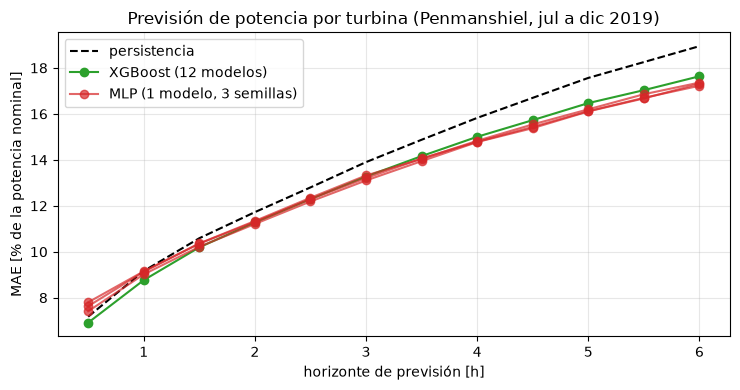

coste de entrenar: XGBoost 156 s para 12 modelos; MLP 17 s por semilla para un solo modelo


In [13]:
HS = [1, 2, 4, 6, 8, 10, 12]
tab3 = pd.DataFrame({"horizonte": [f"{30 * h} min" if h < 2 else f"{h // 2} h" if h % 2 == 0 else f"{30 * h} min" for h in HS]})
tab3["persistencia"] = [pers[h - 1] for h in HS]
tab3["XGBoost"] = [mae_h(pred_x)[h - 1] for h in HS]
tab3["MLP (media 3 semillas)"] = [np.mean([mae_h(p)[h - 1] for p in pred_m]) for h in HS]
tab3["MLP mejor que XGB (semillas)"] = [f"{sum(mae_h(p)[h - 1] < mae_h(pred_x)[h - 1] for p in pred_m)} de 3" for h in HS]
display(tab3.set_index("horizonte").round(2))
medio = pd.Series({"persistencia": pers.mean(), "XGBoost": mae_h(pred_x).mean(),
                   **{f"MLP semilla {s}": mae_h(p).mean() for s, p in enumerate(pred_m)}})
print("MAE medio sobre los 12 horizontes [% de P_nom]:\n", medio.round(2).to_string())
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(1, H + 1) * 0.5
ax.plot(x, pers, "k--", label="persistencia")
ax.plot(x, mae_h(pred_x), "o-", color="tab:green", label="XGBoost (12 modelos)")
for s, p in enumerate(pred_m):
    ax.plot(x, mae_h(p), "o-", color="tab:red", alpha=0.7, label="MLP (1 modelo, 3 semillas)" if s == 0 else None)
ax.set_xlabel("horizonte de previsión [h]"); ax.set_ylabel("MAE [% de la potencia nominal]")
ax.set_title("Previsión de potencia por turbina (Penmanshiel, jul a dic 2019)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"coste de entrenar: XGBoost {t_xgb3:.0f} s para 12 modelos; MLP {np.mean(t_mlp3):.0f} s por semilla para un solo modelo")

**Lectura:**

* **En media sobre los 12 horizontes hay un empate técnico.** XGBoost da 13,23 %, el MLP 13,25, 13,20 y 13,11 % según la semilla, y la persistencia 13,96 %. La mejora sobre persistencia es pequeña en ambos (un 5 a 6 %): prever con 3 horas de historia local a 6 horas vista es difícil.
* **Pero la imagen cambia con el horizonte.** A 30 min gana XGBoost (6,91 % frente a 7,61 %: la red pierde un 10 %, ninguna semilla le gana), y a 1 h también (8,77 % frente a 9,10 %). Hacia 2 h empatan. **Desde 4 h gana el MLP en las tres semillas**: 15,00 % frente a 14,79 % a 4 h, 16,47 % frente a 16,14 % a 5 h y 17,64 % frente a 17,30 % a 6 h (un 2 %).
* **Interpretación.** A corto plazo manda la inercia de la última medida y unos pocos rasgos (los árboles son muy buenos ahí). A largo plazo hay que combinar información de todas las turbinas y entre horizontes (qué viene por el parque), y una representación compartida entre las 168 salidas ayuda un poco. La red, además, aprende todos los horizontes **a la vez**: la información de uno regulariza al resto.
* **Coste.** XGBoost necesita un modelo por horizonte: 156 s para los 12. El MLP entrena **uno solo** en unos 17 s por semilla (unas 9 veces menos), y si hubiera 6 horizontes más o 6 turbinas más seguiría siendo un único modelo. Con 168 salidas esa diferencia de mantenimiento (un artefacto, una validación, una tabla) pesa tanto como el 2 % de precisión.
* **Honestidad.** Con 3 semillas y un solo parque, la ventaja del MLP a largo plazo es pequeña y real (consistente), pero a corto plazo pierde. Una opción híbrida sería XGBoost a menos de 1 h y la red para el resto.
* **Prueba preliminar fuera de este cuaderno (no ejecutada aquí).** Con una red que comparte pesos entre turbinas (se aplica a cualquier parque) y se preentrena en Penmanshiel para ajustarla con 2 semanas, 1 mes o 3 meses de Kelmarsh, el error de la red quedó entre un 2 % mejor y un 1 % peor que el de XGBoost preentrenado y continuado, sin ganador claro. La transferencia entre parques funciona con ambos si se hace bien.


## 6. Mapa de decisión: cuándo merece la pena PyTorch

La tabla resume con un número cada situación medida. Se calcula con las variables de las secciones anteriores.

In [14]:
pq = lambda x, d=1: f"{x:.{d}f}".replace(".", ",")
r_small, r_big = res1.iloc[1], res1.iloc[-1]
B = "B. fuera de rango"
h1, h12 = tab3.iloc[0], tab3.iloc[-1]
t2 = lambda k: tabla2.loc[k, B]
mapa = pd.DataFrame([
    ("1. Pocos datos tabulares (2 000 filas)", f"XGBoost {pq(r_small.xgb_kW)} kW", f"MLP {pq(r_small.mlp_kW)} kW", "XGBoost"),
    ("2. Muchos datos tabulares (268 000 filas)", f"XGBoost {pq(r_big.xgb_kW)} kW en {pq(r_big.xgb_s)} s", f"MLP {pq(r_big.mlp_kW)} kW en {pq(r_big.mlp_s_por_semilla)} s", "XGBoost, por poco y mucho más barato"),
    ("3. Salir del rango visto, sin ingeniería de rasgos", f"XGBoost directo {pq(t2('XGBoost, objetivo directo'), 2)} m/s", f"MLP con salto lineal {pq(t2('MLP con salto lineal'), 2)} m/s", f"PyTorch gana a XGBoost, pero Ridge ({pq(t2('regresión lineal (Ridge)'), 2)}) gana a ambos"),
    ("4. Salir del rango visto, con la física en el objetivo", f"XGBoost cociente {pq(t2('XGBoost, objetivo = cociente con ws_141'), 2)} m/s", f"MLP con salto lineal {pq(t2('MLP con salto lineal'), 2)} m/s", "XGBoost"),
    ("5. Previsión a 30 min, 14 turbinas", f"XGBoost {pq(h1['XGBoost'])} %", f"MLP {pq(h1['MLP (media 3 semillas)'])} %", "XGBoost"),
    ("6. Previsión a 6 h, 14 turbinas", f"XGBoost {pq(h12['XGBoost'])} %", f"MLP {pq(h12['MLP (media 3 semillas)'])} %", "PyTorch, por poco (3 de 3 semillas)"),
    ("7. Coste de 12 horizontes x 14 turbinas", f"XGBoost {pq(t_xgb3, 0)} s (12 modelos)", f"MLP {pq(np.mean(t_mlp3), 0)} s por semilla (1 modelo)", "PyTorch"),
], columns=["Situación", "XGBoost", "PyTorch", "Mejor"])
mapa.set_index("Situación")

,XGBoost,PyTorch,Mejor
Situación,,,
1. Pocos datos tabulares (2 000 filas),"XGBoost 37,6 kW","MLP 43,2 kW",XGBoost
2. Muchos datos tabulares (268 000 filas),"XGBoost 30,9 kW en 14,4 s","MLP 31,3 kW en 44,0 s","XGBoost, por poco y mucho más barato"
"3. Salir del rango visto, sin ingeniería de rasgos","XGBoost directo 5,43 m/s","MLP con salto lineal 1,32 m/s","PyTorch gana a XGBoost, pero Ridge (0,84) gana..."
"4. Salir del rango visto, con la física en el objetivo","XGBoost cociente 0,92 m/s","MLP con salto lineal 1,32 m/s",XGBoost
"5. Previsión a 30 min, 14 turbinas","XGBoost 6,9 %","MLP 7,6 %",XGBoost
"6. Previsión a 6 h, 14 turbinas","XGBoost 17,6 %","MLP 17,3 %","PyTorch, por poco (3 de 3 semillas)"
7. Coste de 12 horizontes x 14 turbinas,XGBoost 156 s (12 modelos),MLP 17 s por semilla (1 modelo),PyTorch


**Cuándo usar XGBoost (u otro modelo clásico) primero**

1. **Datos tabulares, de dimensión baja a media, y pocas filas** (de cientos a decenas de miles): XGBoost gana con holgura (experimento 1) y se entrena en segundos.
2. **Hay conocimiento del dominio que se puede poner en el objetivo o en los rasgos** (un cociente, una razón de cizalladura, una curva de potencia): un modelo simple o XGBoost con un buen objetivo suele ser más fiable que una red, también fuera de rango (experimento 2).
3. **Hace falta rapidez de iteración, interpretabilidad (importancia de rasgos) y pocos riesgos de despliegue.**

**Cuándo merece la pena PyTorch**

1. **Entradas con estructura que no cabe en una tabla.** Es el caso decisivo. Una imagen, un grafo o una señal continua no se convierten en columnas sin perder justo lo que importa:
   * **Imágenes:** las del radar de apertura sintética (SAR) del cuaderno 03 son un ejemplo directo. La textura de la rugosidad del mar que revela la longitud de onda y la dirección del oleaje se aprende con redes convolucionales; **XGBoost no tiene equivalente**, porque los árboles no comparten pesos entre posiciones del píxel ni conocen la vecindad espacial.
   * **Grafos:** una granja eólica con estelas (cuaderno 02), donde el modelo debe aplicarse a otro número de turbinas.
   * **Física en la pérdida:** perfiles de viento con la ecuación de Monin-Obukhov (cuaderno 01).
2. **Muchas salidas relacionadas** (varios horizontes, varias turbinas, varias alturas): un solo modelo con representación compartida. En el experimento 3 es unas 9 veces más barato de entrenar y algo mejor a partir de 4 h.
3. **Pérdidas a medida o restricciones** (cuantiles conjuntos sin cruces, penalizar errores según el valor económico de la energía, derivadas con respecto a la entrada): se escriben en unas líneas con autodiferenciación.
4. **Preentrenamiento y transferencia** entre parques o sensores, y **datos muy abundantes** donde el modelo grande acaba compensando su coste.
5. **Despliegue en un entorno ya preparado para redes** (exportación a ONNX (formato abierto de intercambio de modelos, *Open Neural Network Exchange*), aceleradores, móviles).

**Qué debe preocuparte con una red**

* **El rango de entrada.** Una red extrapola, pero sin garantías (experimento 2, donde ni siquiera mejoró a la persistencia). Monitoriza si los datos nuevos salen del rango visto.
* **Las semillas.** Reporta la media y el rango, no una sola ejecución. En el experimento 1 el MLP varía entre 57,6 y 68,6 kW con 500 filas.
* **Un rival débil engaña.** Es frecuente que una comparación de redes frente a árboles use árboles sin parada temprana, sin los rasgos adecuados o con la pérdida equivocada (aquí XGBoost usó L1 para evaluar con MAE).


## 7. Limitaciones y ejercicios

**Limitaciones**

* Un solo parque (Penmanshiel) y un único lidar (K13A) como casos principales; las conclusiones sobre el horizonte y el rango pueden cambiar con otros datos.
* El SCADA está promediado a 30 min. Con datos de 1 Hz y señales de vibración, el balance cambia a favor de las redes.
* No se ha ajustado a fondo ninguna arquitectura. Con más tiempo, la red del experimento 3 podría usar capas compartidas entre turbinas y la del 1 más regularización, y XGBoost se podría afinar con búsqueda de hiperparámetros.
* En el experimento 2 la división B es extrema (viento máximo 11 m/s en entrenamiento y 32 m/s en test) a propósito, para mostrar el límite de los árboles.

**Ejercicios**

1. En el experimento 1, añade a XGBoost la potencia de la turbina en el instante anterior como rasgo. ¿Se amplía su ventaja?
2. En el experimento 2, haz que la red prediga también el cociente con ws_141. ¿Alcanza al XGBoost con cociente?
3. En el experimento 3, combina: XGBoost para los horizontes menores o iguales a 1 h y el MLP para el resto. ¿Cuánto baja el MAE medio?
4. Prueba un MLP que **comparta pesos entre turbinas** en el experimento 3 y se aplique a Kelmarsh sin reentrenar.

**Referencias**

* Chen, T. y Guestrin, C. (2016). *XGBoost: a scalable tree boosting system*. Proceedings of the 22nd ACM SIGKDD, 785-794. [doi:10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785), [arXiv:1603.02754](https://arxiv.org/abs/1603.02754).
* Kingma, D. P. y Ba, J. (2015). *Adam: a method for stochastic optimization*. ICLR. [arXiv:1412.6980](https://arxiv.org/abs/1412.6980).
* Penmanshiel y Kelmarsh (SCADA, CC BY 4.0): [doi:10.5281/zenodo.5946808](https://doi.org/10.5281/zenodo.5946808) (Penmanshiel) y [doi:10.5281/zenodo.5841834](https://doi.org/10.5281/zenodo.5841834) (Kelmarsh), Zenodo.
* Lidar K13A: [portal de mediciones de viento marino de TNO](https://offshorewind-measurements.tno.nl) (y [RVO](https://offshorewind.rvo.nl)).

In [15]:
print(f"Tiempo total de ejecución del notebook: {time.time() - T0:.0f} s")

Tiempo total de ejecución del notebook: 588 s
